# Week 6 — Forecasting in Pharma: the Patient Funnel
**Applied Data Science and AI in Pharma Commercial · Columbia DSI · Fall 2026 · Monday, October 19**

**The case.** LYMBREXA is a fictional third-in-class bispecific antibody for relapsed DLBCL: 3L+ launch in January 2027, a 2L label expected mid-2028. Two people need a forecast:

- **Brand lead (budget):** monthly patients, vials and revenue for 2027–2028.
- **Portfolio strategy (long-range plan, LRP):** annual revenue to 2041. The plan on file says **$250M in 2029** and **$400M at peak**. Forecast or wish?

**The approach.** One simple patient funnel, driven by a documented **assumption book**. Every number traces to a row of `lymbrexa_assumptions.csv` with a low / base / high, a source and a rationale. Data is used to *justify assumptions*, not to fit complicated models. The same model is in `Week_06_LYMBREXA_Forecast_Model.xlsx`.

| § | Step |
|---|---|
| 1 | The assumption book |
| 2 | From data to assumptions: progression, persistence, uptake, share |
| 3 | The patient funnel (incidence model) and a check against the market |
| 4 | The brand forecast: LRP (annual) and budget (monthly) |
| 5 | Scenarios and the tornado |
| 6 | Checks: market trend, regional split, loss of exclusivity |
| 7 | The prevalence model: GLUCOREN in type 2 diabetes |

All data are synthetic.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from pathlib import Path
warnings.filterwarnings("ignore"); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 70)
NAVY, CORAL, ICE, GREY, TEAL, GOLD = "#1E2761", "#FF6B6B", "#CADCFC", "#888888", "#2A9D8F", "#E8B04B"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
DATA = next((p for p in [Path("data"), Path(".")] if (p / "lymbrexa_assumptions.csv").exists()), Path("."))
IMG = next((p for p in [Path("../Instructor material/instructor material_w6/build/img"), Path("instructor material/build/img")] if p.exists()), None)
def savefig(name):
    if IMG is not None: plt.savefig(IMG / name, bbox_inches="tight", dpi=150)

## §1 · The assumption book

A forecast is a list of assumptions multiplied together. Write each one down with a **range**, a **source** and a **reason**. The forecast review is a review of this table.

In [2]:
book = pd.read_csv(DATA / "lymbrexa_assumptions.csv")
book[["id", "category", "assumption", "unit", "low", "base", "high", "source_type"]]

,id,category,assumption,unit,low,base,high,source_type
0,E0,Epidemiology,"Incident DLBCL cases, 2016–2030",cases / yr,×0.95,dlbcl_epi_inputs.csv,×1.05,Data (synthetic)
1,E1,Epidemiology,Incident-case growth after 2030,% / yr,0.015,0.023,0.03,Data (synthetic)
2,E2,Epidemiology,Diagnosed and presenting,% of cases,0.95,0.97,0.98,Data (synthetic)
3,T1,Treatment,Treated in 1L,% of diagnosed,0.82,0.86,0.89,Data (synthetic)
4,T2,Treatment,"Progress to 2L (lifetime), one year later",% of 1L,0.26,0.31,0.36,Data + literature
5,T3,Treatment,"Progress to 3L (lifetime), one year later",% of 2L,0.43,0.5,0.57,Data + judgment
6,T4,Treatment,Later-lines multiplier (3L+ starts per 3L patient),×,1.14,1.24,1.34,Data (synthetic)
7,T5,Treatment,Lag between lines,years,1,1,1,Simplification
8,B1,Brand,3L+ launch year,year,2027,2027,2027,Regulatory plan
9,B2,Brand,2L label — first full year,year,2030,2029,2028,Regulatory plan


In [3]:
# One helper: the numeric value of an assumption under a scenario. 'low' = pessimistic, 'high' = optimistic.
def assumptions(scenario="base", swing=None):
    """Return {id: value}. swing = {id: 'low'|'high'} moves single assumptions (for the tornado)."""
    v = {}
    for _, r in book.iterrows():
        s = (swing or {}).get(r.id, scenario)
        if r.id == "E0": v["E0"] = {"low": 0.95, "base": 1.0, "high": 1.05}[s]; continue
        try: v[r.id] = float(r[s])
        except (TypeError, ValueError): pass
    return v
v = assumptions(); {k: v[k] for k in ["T2", "T3", "B3", "B4", "D1", "P2"]}

{'T2': 0.31, 'T3': 0.5, 'B3': 0.15, 'B4': 0.1, 'D1': 6.0, 'P2': 0.76}

## §2 · From data to assumptions

Four assumptions matter most. Each gets one quick look at the data.

### 2a · Progression rates (T2, T3) — Kaplan–Meier on the Week 2 cohort
Many patients diagnosed recently have not had time to relapse: they are **censored**, not cured. Counting "patients who reached the next line" understates the lifetime rate. Kaplan–Meier fixes that (Kaplan & Meier 1958).

1L to 2L: naive 28% · Kaplan–Meier lifetime 36% · median time among those who progressed 14 months
2L to 3L: naive 48% · Kaplan–Meier lifetime 61% · median time among those who progressed 9 months


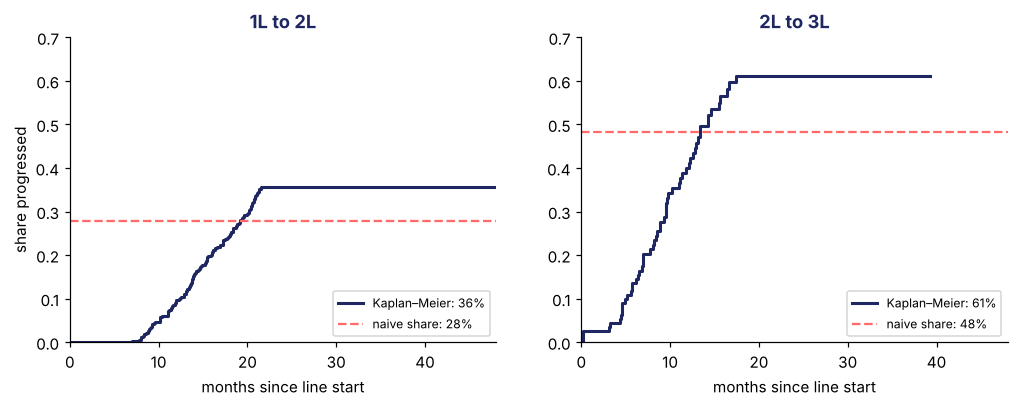

Assumption book: T2 = 31% (KM 36% on a treated claims cohort, trimmed for frail patients not re-treated), T3 = 50%, lag = 1 year (T5).


In [4]:
ttnl = pd.read_csv(DATA / "dlbcl_time_to_next_line.csv")   # one row per patient: months to next line, progressed (1) or censored (0)
def kaplan_meier(months, event):
    d = pd.DataFrame({"t": months, "e": event}).sort_values("t"); S, curve = 1.0, [(0, 1.0)]
    for t, g in d.groupby("t"):
        at_risk = (d.t >= t).sum(); S *= 1 - g.e.sum() / at_risk; curve.append((t, S))
    return pd.DataFrame(curve, columns=["months", "S"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a, (name, g) in zip(ax, ttnl.groupby("transition")):
    km = kaplan_meier(g.months, g.progressed); lifetime = 1 - km.S.iloc[-1]
    a.step(km.months, 1 - km.S, where="post", color=NAVY, lw=2, label=f"Kaplan–Meier: {lifetime:.0%}")
    a.axhline(g.progressed.mean(), color=CORAL, ls="--", label=f"naive share: {g.progressed.mean():.0%}")
    a.set_title(name, color=NAVY, fontweight="bold"); a.set_xlabel("months since line start"); a.set_ylim(0, 0.7); a.set_xlim(0, 48); a.legend(loc="lower right", fontsize=8)
    print(f"{name}: naive {g.progressed.mean():.0%} · Kaplan–Meier lifetime {lifetime:.0%} · median time among those who progressed {g[g.progressed == 1].months.median():.0f} months")
ax[0].set_ylabel("share progressed"); savefig("km_progression.png"); plt.show()
print("Assumption book: T2 = 31% (KM 36% on a treated claims cohort, trimmed for frail patients not re-treated), T3 = 50%, lag = 1 year (T5).")

### 2b · Persistence (D1) — how long a patient stays on therapy
**Persistence** is the time from starting to stopping therapy (Cramer et al. 2008). The forecast needs the *average* months on therapy. Again, Kaplan–Meier handles patients still on therapy at the data cut.

Bispecific A (treat to progression)           KM mean 9.4 months · naive mean 7.1 (biased low: censored patients are still on)
Bispecific B (fixed 12 cycles)                KM mean 8.3 months · naive mean 6.9 (biased low: censored patients are still on)
Oral XPO1 inhibitor (treat to progression)    KM mean 5.9 months · naive mean 5.2 (biased low: censored patients are still on)


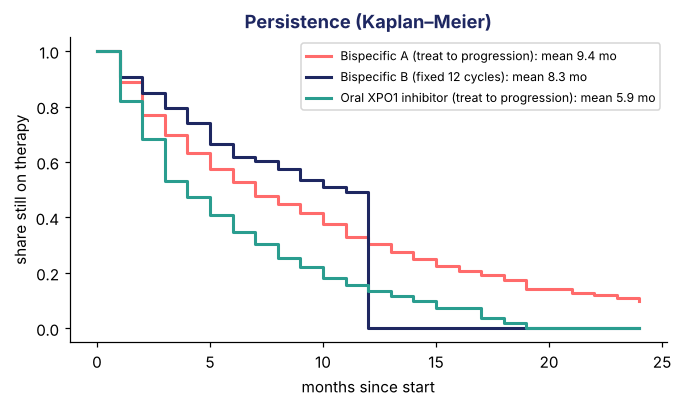

Assumption book: D1 = 6 months (label caps LYMBREXA at 8 cycles; early stops bring the mean to ~6). Range 5–7.5.


In [5]:
pers = pd.read_csv(DATA / "regimen_persistence_patients.csv")
fig, ax = plt.subplots(figsize=(7, 3.6))
for (reg, g), c in zip(pers.groupby("regimen"), [CORAL, NAVY, TEAL]):
    km = kaplan_meier(g.months_on_therapy, 1 - g.censored)
    grid = np.arange(0, 25); S = np.array([km[km.months <= m].S.iloc[-1] for m in grid]); mean_months = S[:-1].sum()
    ax.step(grid, S, where="post", color=c, lw=2, label=f"{reg}: mean {mean_months:.1f} mo")
    print(f"{reg:45s} KM mean {mean_months:.1f} months · naive mean {g.months_on_therapy.mean():.1f} (biased low: censored patients are still on)")
ax.set_xlabel("months since start"); ax.set_ylabel("share still on therapy"); ax.legend(fontsize=8); ax.set_title("Persistence (Kaplan–Meier)", color=NAVY, fontweight="bold")
savefig("km_persistence.png"); plt.show()
print("Assumption book: D1 = 6 months (label caps LYMBREXA at 8 cycles; early stops bring the mean to ~6). Range 5–7.5.")

### 2c · Uptake (U1–U4) — how fast share builds, from analog launches
Instead of fitting a diffusion model, read the analogs: what share of their eventual peak did similar launches reach in years 1, 2 and 3? (The Bass model, Bass 1969, is the formal version of the same S-curve.)

                          analog  peak_share  year1  year2  year3
                       ADC combo        0.18   0.28   0.99   1.06
                 ADC in 1L combo        0.29   0.24   0.89   1.00
   Bispecific A (first in class)        0.26   0.37   0.95   1.01
Bispecific B (second, +4 months)        0.17   0.29   0.89   0.99
                         CAR-T A        0.20   0.08   0.49   0.94
                         CAR-T B        0.20   0.12   0.63   0.98
             Oral XPO1 inhibitor        0.04   0.15   0.43   0.90
                mAb + IMiD combo        0.10   0.17   0.73   0.98


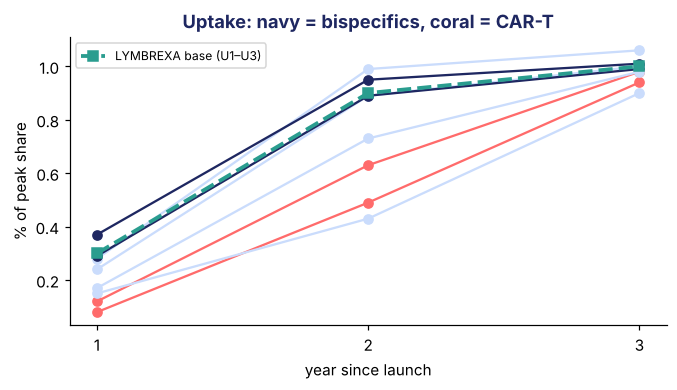

Assumption book: 30% / 90% / 100% of peak in years 1–3 (outpatient analogs). Low case = a CAR-T-like start.


In [6]:
an = pd.read_csv(DATA / "analog_launches_monthly.csv")
ramp = []
for name, g in an.groupby("analog"):
    s = g.share_of_line_starts.values; peak = s[-6:].mean()
    ramp.append(dict(analog=name, peak_share=round(peak, 2), year1=s[:12].mean() / peak, year2=s[12:24].mean() / peak, year3=s[24:36].mean() / peak))
ramp = pd.DataFrame(ramp).round(2); print(ramp.to_string(index=False))
fig, ax = plt.subplots(figsize=(7, 3.4))
for _, r in ramp.iterrows():
    ax.plot([1, 2, 3], [r.year1, r.year2, r.year3], "o-", color=CORAL if "CAR-T" in r.analog else (NAVY if "Bispecific" in r.analog else ICE), lw=1.5)
ax.plot([1, 2, 3], [v["U1"], v["U2"], v["U3"]], "s--", color=TEAL, lw=2.5, label="LYMBREXA base (U1–U3)")
ax.set_xticks([1, 2, 3]); ax.set_xlabel("year since launch"); ax.set_ylabel("% of peak share"); ax.legend(fontsize=8); ax.set_title("Uptake: navy = bispecifics, coral = CAR-T", color=NAVY, fontweight="bold")
savefig("uptake_analogs.png"); plt.show()
print("Assumption book: 30% / 90% / 100% of peak in years 1–3 (outpatient analogs). Low case = a CAR-T-like start.")

### 2d · Peak share (B3) and coverage (C1)
- **Order of entry.** For packaged goods and prescription anti-ulcer drugs, an entrant's share ≈ the pioneer's share ÷ √(order of entry) (Kalyanaram, Robinson & Urban 1995). The pioneer bispecific analog peaked at 0.26, so a third entrant's prior is 0.26 × 1/√3 = **0.15**.
- **Coverage.** A few prescribers write most of the volume, so formulary access at the largest centers sets year-1 coverage.

In [7]:
print(f"Order-of-entry prior for a 3rd entrant: 0.26 / √3 = {0.26 / 3 ** 0.5:.2f}  → B3 base 0.15")
presc = pd.read_csv(DATA / "dlbcl_prescriber_3Lplus_starts.csv").sort_values("starts_3Lplus_12m", ascending=False)
cum = presc.starts_3Lplus_12m.cumsum() / presc.starts_3Lplus_12m.sum(); n = len(presc)
print(f"Top 10% of prescribers write {cum.iloc[n // 10 - 1]:.0%} of 3L+ starts; top 20% write {cum.iloc[n // 5 - 1]:.0%}.  → C1 = 70% coverage in year 1")

Order-of-entry prior for a 3rd entrant: 0.26 / √3 = 0.15  → B3 base 0.15
Top 10% of prescribers write 53% of 3L+ starts; top 20% write 68%.  → C1 = 70% coverage in year 1


## §3 · The patient funnel — an incidence model

Each line multiplies the previous one by a rate. Progression happens with a one-year lag (T5).

`1L(y) = cases(y) × diagnosed × treated` · `2L(y) = 1L(y−1) × progress to 2L` · `3L+(y) = 2L(y−1) × progress to 3L × later lines`

In [8]:
epi = pd.read_csv(DATA / "dlbcl_epi_inputs.csv").groupby("year").incident_cases.sum()
def funnel(v):
    cases = {y: (epi.get(y, epi.loc[2030] * (1 + v["E1"]) ** (y - 2030))) * v["E0"] for y in range(2022, 2042)}
    f = pd.DataFrame(index=range(2022, 2042)); f["cases"] = pd.Series(cases)
    f["treated_1L"] = f.cases * v["E2"] * v["T1"]
    f["starts_2L"] = f.treated_1L.shift(1) * v["T2"]
    f["starts_3Lplus"] = f.starts_2L.shift(1) * v["T3"] * v["T4"]
    return f.loc[2023:]
f = funnel(v); f.loc[[2025, 2027, 2029, 2035, 2041]].round(0)

,cases,treated_1L,starts_2L,starts_3Lplus
2025,21913.0,18280.0,5544.0,3363.0
2027,22910.0,19112.0,5794.0,3513.0
2029,23966.0,19992.0,6059.0,3673.0
2035,27471.0,22917.0,6944.0,4209.0
2041,31487.0,26267.0,7960.0,4824.0


     observed 2025  funnel 2025 difference
1L         17930.0      18280.0        +2%
2L          5468.0       5544.0        +1%
3L+         3471.0       3363.0        -3%


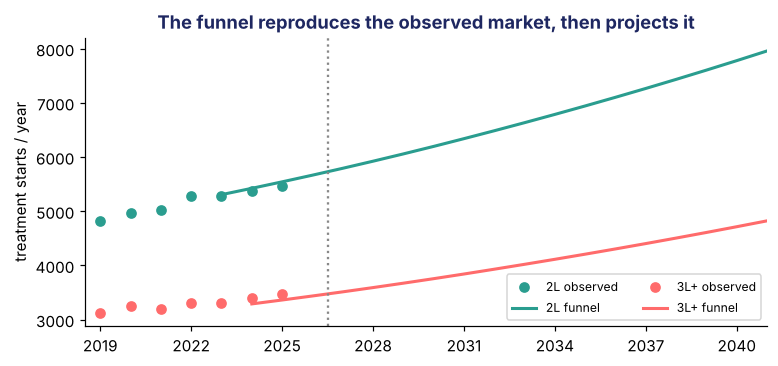

In [9]:
market = pd.read_csv(DATA / "dlbcl_market_monthly.csv"); market["year"] = market.month.str[:4].astype(int)
obs = market[market.year <= 2025].groupby("year")[["starts_1L", "starts_2L", "starts_3Lplus"]].sum()
check = pd.DataFrame({"observed 2025": obs.loc[2025].values, "funnel 2025": f.loc[2025, ["treated_1L", "starts_2L", "starts_3Lplus"]].values}, index=["1L", "2L", "3L+"])
check["difference"] = (check["funnel 2025"] / check["observed 2025"] - 1).map("{:+.0%}".format); print(check.round(0))
fig, ax = plt.subplots(figsize=(8, 3.4))
for col, c, lab in [("starts_2L", TEAL, "2L"), ("starts_3Lplus", CORAL, "3L+")]:
    ax.plot(obs.index, obs[col], "o", color=c, label=f"{lab} observed"); ax.plot(f.index, f[col], color=c, lw=2, label=f"{lab} funnel")
ax.axvline(2026.5, color=GREY, ls=":"); ax.set_xlim(2018.5, 2041); ax.set_xticks(range(2019, 2042, 3)); ax.legend(fontsize=8, ncol=2); ax.set_ylabel("treatment starts / year"); ax.set_title("The funnel reproduces the observed market, then projects it", color=NAVY, fontweight="bold")
savefig("funnel_vs_market.png"); plt.show()

## §4 · The brand forecast

`brand share = peak share × uptake(year since launch) × coverage × LOE retention` · `new patients = line starts × brand share`
`patients on therapy = new patients × months on therapy ÷ 12` (Little's law) · `revenue = new patients × months × compliance × price × gross-to-net`

In [10]:
def brand(v):
    f = funnel(v); out = pd.DataFrame(index=f.index)
    def share(peak, launch):
        s = []
        for y in f.index:
            k = int(y - launch + 1)
            if k < 1: s.append(0.0); continue
            uptake = [v["U1"], v["U2"], v["U3"], v["U4"]][min(k, 4) - 1]
            coverage = v["C1"] if k == 1 else v["C2"]
            loe = 1.0 if y < v["L1"] else (v["L2"] if y == v["L1"] else v["L3"])
            s.append(peak * uptake * coverage * loe)
        return pd.Series(s, index=f.index)
    out["new_3Lplus"] = f.starts_3Lplus.fillna(0) * share(v["B3"], v["B1"])
    out["new_2L"] = f.starts_2L * share(v["B4"], v["B2"])
    out["new_patients"] = out.new_3Lplus + out.new_2L
    out["on_therapy_avg"] = out.new_patients * v["D1"] / 12
    out["net_revenue_musd"] = out.new_patients * v["D1"] * v["D2"] * v["P1"] * v["P2"] / 1e6
    return out
lrp = brand(v)
print("LONG-RANGE PLAN (annual)"); print(lrp.loc[2027:].round(1).to_string())
print(f"\n2029: ${lrp.loc[2029, 'net_revenue_musd']:.0f}M (plan: $250M) · peak ${lrp.net_revenue_musd.max():.0f}M in {lrp.net_revenue_musd.idxmax()} (plan: $400M)")

LONG-RANGE PLAN (annual)
      new_3Lplus  new_2L  new_patients  on_therapy_avg  net_revenue_musd
2027       110.7     0.0         110.7            55.3               8.9
2028       460.7     0.0         460.7           230.3              36.9
2029       523.4   127.2         650.7           325.3              52.1
2030       535.3   529.9        1065.2           532.6              85.4
2031       547.6   602.4        1149.9           575.0              92.2
2032       560.2   616.2        1176.4           588.2              94.3
2033       573.1   630.4        1203.5           601.7              96.4
2034       586.3   644.9        1231.2           615.6              98.7
2035       599.7   659.7        1259.5           629.7             100.9
2036       613.5   674.9        1288.4           644.2             103.3
2037       627.7   690.4        1318.1           659.0             105.6
2038       642.1   706.3        1348.4           674.2             108.1
2039       492.6   541.9  

BUDGET (monthly)
  month  new_patients  on_therapy  net_revenue_musd  vials
2027-01           1.4         8.5               0.1    8.1
2027-03           4.3        25.5               0.3   24.3
2027-06           8.5        51.1               0.7   48.5
2027-09          12.8        76.6               1.0   72.8
2027-12          17.0       102.2               1.4   97.1
2028-01          38.4       230.3               3.1  218.8
2028-12          38.4       230.3               3.1  218.8


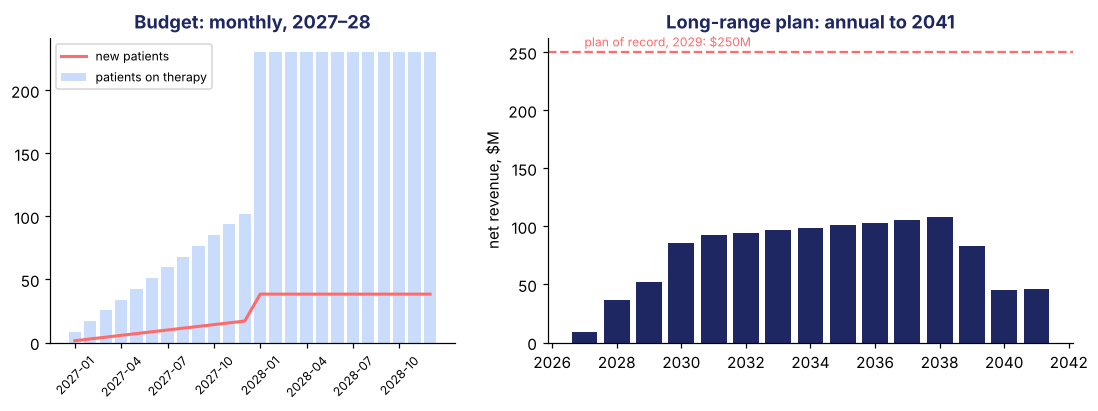

In [11]:
# BUDGET = the LRP's 2027–28 values phased by month (F1: linear ramp in the launch year; F2: flat after)
rows = []
for y in [2027, 2028]:
    w = [m / 78 for m in range(1, 13)] if y == v["B1"] else [1 / 12] * 12
    for m in range(12):
        rows.append(dict(month=f"{y}-{m + 1:02d}", new_patients=lrp.loc[y, "new_patients"] * w[m], on_therapy=lrp.loc[y, "on_therapy_avg"] * 12 * w[m], net_revenue_musd=lrp.loc[y, "net_revenue_musd"] * w[m]))
bud = pd.DataFrame(rows); bud["vials"] = bud.on_therapy * v["D2"]
print("BUDGET (monthly)"); print(bud.iloc[[0, 2, 5, 8, 11, 12, 23]].round(1).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1, 1.3]})
ax[0].bar(bud.month, bud.on_therapy, color=ICE, label="patients on therapy"); ax[0].plot(bud.month, bud.new_patients, color=CORAL, lw=2, label="new patients")
ax[0].set_xticks(bud.month[::3]); ax[0].tick_params(axis="x", rotation=45, labelsize=8); ax[0].legend(fontsize=8); ax[0].set_title("Budget: monthly, 2027–28", color=NAVY, fontweight="bold")
ax[1].bar(lrp.loc[2027:].index, lrp.loc[2027:].net_revenue_musd, color=NAVY); ax[1].axhline(250, color=CORAL, ls="--"); ax[1].text(2027, 255, "plan of record, 2029: $250M", color=CORAL, fontsize=8)
ax[1].set_ylabel("net revenue, $M"); ax[1].set_title("Long-range plan: annual to 2041", color=NAVY, fontweight="bold")
savefig("budget_lrp.png"); plt.show()

## §5 · Scenarios and the tornado

- **Scenarios:** every assumption at its low, base or high together. Deliberately extreme — the outer edges, not a likely case.
- **Tornado:** move one assumption at a time to its low and high. It ranks where evidence is worth buying.

       low   base   high
2027   1.0    9.0   37.0
2028   7.0   37.0  148.0
2029  11.0   52.0  228.0
2032  28.0   94.0  251.0
2035  30.0  101.0  274.0
Peak: low $31M · base $108M · high $308M


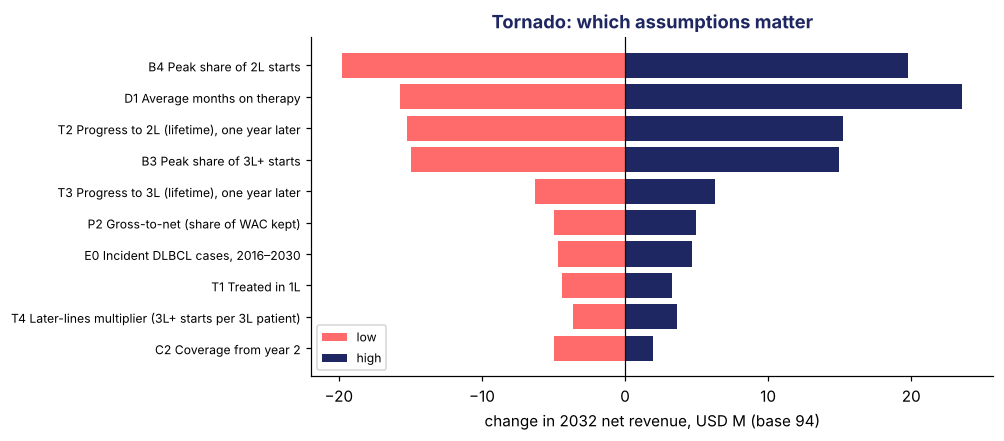

In [12]:
sc = pd.DataFrame({s: brand(assumptions(s)).net_revenue_musd for s in ["low", "base", "high"]})
print(sc.loc[[2027, 2028, 2029, 2032, 2035]].round(0).to_string())
print(f"Peak: low ${sc.low.max():.0f}M · base ${sc.base.max():.0f}M · high ${sc.high.max():.0f}M")
YEAR = 2032; base = sc.loc[YEAR, "base"]; rows = []
for _, r in book.iterrows():
    if r.id in ("T5", "P1", "B1", "U4", "F1", "F2"): continue
    lo, hi = brand(assumptions(swing={r.id: "low"})).loc[YEAR, "net_revenue_musd"], brand(assumptions(swing={r.id: "high"})).loc[YEAR, "net_revenue_musd"]
    if abs(hi - lo) > 1e-6: rows.append(dict(assumption=f"{r.id} {r.assumption}", low=lo - base, high=hi - base))
tor = pd.DataFrame(rows).assign(swing=lambda d: (d.high - d.low).abs()).sort_values("swing").tail(10)
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(tor.assumption, tor.low, color=CORAL, label="low"); ax.barh(tor.assumption, tor.high, color=NAVY, label="high"); ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel(f"change in {YEAR} net revenue, USD M (base {base:.0f})"); ax.legend(fontsize=8); ax.set_title("Tornado: which assumptions matter", color=NAVY, fontweight="bold"); ax.tick_params(axis="y", labelsize=8)
savefig("tornado.png"); plt.show()

## §6 · Three checks

### 6a · Does the market trend agree with the funnel?
Time series has a narrow job here: project the **market** (not the brand) and compare it with the funnel. One standard method — exponential smoothing (ETS; Hyndman & Athanasopoulos, FPP3 ch. 8) — tested on the last 12 months it did not see, against a "same as last year" benchmark.

In [13]:
try:
    from statsforecast import StatsForecast
    from statsforecast.models import AutoETS, SeasonalNaive
    m = market[["month", "starts_3Lplus"]].rename(columns={"month": "ds", "starts_3Lplus": "y"}); m["ds"] = pd.to_datetime(m.ds); m["unique_id"] = "3L+"
    train, test = m.iloc[:-12], m.iloc[-12:]
    fc = StatsForecast(models=[AutoETS(season_length=12), SeasonalNaive(season_length=12)], freq="MS").forecast(df=train, h=12)
    for mdl in ["AutoETS", "SeasonalNaive"]: print(f"{mdl:14s} average error on the hidden year: {np.mean(np.abs(fc[mdl].values - test.y.values)) / test.y.mean():.1%}")
    fc2 = StatsForecast(models=[AutoETS(season_length=12)], freq="MS").forecast(df=m, h=18)
    ets_2027 = fc2[fc2.ds.dt.year == 2027].AutoETS.sum()
    print(f"3L+ starts in 2027 — trend (ETS): {ets_2027:,.0f} · funnel: {f.loc[2027, 'starts_3Lplus']:,.0f} · gap {ets_2027 / f.loc[2027, 'starts_3Lplus'] - 1:+.0%}")
except ImportError:
    print("pip install statsforecast to run this check")
print("If the two disagree by more than a few percent, find out why before the review. Foundation models (Chronos, TimesFM) do the same job zero-shot for many series at once — they cannot forecast a launch.")

AutoETS        average error on the hidden year: 4.6%
SeasonalNaive  average error on the hidden year: 6.7%
3L+ starts in 2027 — trend (ETS): 3,574 · funnel: 3,513 · gap +2%
If the two disagree by more than a few percent, find out why before the review. Foundation models (Chronos, TimesFM) do the same job zero-shot for many series at once — they cannot forecast a launch.


### 6b · Split the national forecast by region and account type
The field needs targets by account; supply needs regions. The simplest coherent method is **top-down**: split the national number by last year's shares. Every piece adds back to the national total. (More advanced methods reconcile forecasts made at every level — FPP3 ch. 11.)

In [14]:
hier = pd.read_csv(DATA / "dlbcl_market_by_region_account.csv")
last = hier[(hier.line == "3Lplus") & (hier.month >= "2025-07")].groupby(["region", "account_type"]).treatment_starts.sum()
split = (last / last.sum()).rename("share").to_frame()
for y in [2027, 2028]: split[f"new patients {y}"] = split.share * lrp.loc[y, "new_patients"]
print(split.round(2).to_string()); print("Check — sums equal the national forecast:", split[["new patients 2027", "new patients 2028"]].sum().round(1).tolist(), "vs", lrp.loc[[2027, 2028], "new_patients"].round(1).tolist())

                        share  new patients 2027  new patients 2028
region    account_type                                             
Midwest   Academic/ATC   0.13              14.27              59.39
          Community      0.07               8.12              33.80
Northeast Academic/ATC   0.12              13.81              57.49
          Community      0.07               7.78              32.37
South     Academic/ATC   0.24              27.00             112.39
          Community      0.14              15.19              63.24
West      Academic/ATC   0.15              16.11              67.07
          Community      0.08               8.39              34.93
Check — sums equal the national forecast: [110.7, 460.7] vs [110.7, 460.7]


### 6c · Loss of exclusivity: use other molecules' history
Nothing in a brand's own history predicts its patent expiry. Use benchmarks: one year after generic entry, U.S. brands kept on average **23% of units** (Grabowski et al. 2021). LYMBREXA is a biologic — biosimilar erosion is slower — so its book assumes 40% retained after the LOE year (L3), a documented judgment. GLUCOREN, a small molecule, uses the 23% benchmark below.

In [15]:
gl = pd.read_csv(DATA / "glucoren_monthly_trx.csv"); gl["year"] = gl.month.str[:4].astype(int)
annual = gl[gl.year <= 2025].groupby("year").trx.sum()
trend = annual.loc[2025] * (annual.loc[2025] / annual.loc[2024]) ** np.arange(1, 6)          # simple: continue last year's growth
retained = np.array([1.0, 0.62, 0.23, 0.20, 0.18])                                            # LOE Jul 2027: half a year of erosion in 2027, then the benchmark
loe = pd.DataFrame({"trend, no LOE": trend, "share retained": retained, "TRx forecast": trend * retained}, index=range(2026, 2031))
print(loe.style.format({"trend, no LOE": "{:,.0f}", "share retained": "{:.0%}", "TRx forecast": "{:,.0f}"}).to_string() if False else loe.assign(**{"trend, no LOE": loe["trend, no LOE"].round(-2), "TRx forecast": loe["TRx forecast"].round(-2)}).to_string(formatters={"trend, no LOE": "{:,.0f}".format, "share retained": "{:.0%}".format, "TRx forecast": "{:,.0f}".format}))

     trend, no LOE share retained TRx forecast
2026       308,600           100%      308,600
2027       304,300            62%      188,700
2028       300,100            23%       69,000
2029       295,900            20%       59,200
2030       291,700            18%       52,500


## §7 · The prevalence model: GLUCOREN in type 2 diabetes

A chronic disease is modeled from **people living with the condition** (prevalence), not new cases. Each year stands alone — a snapshot. Prevalence ≈ incidence × duration (CDC, *Principles of Epidemiology*).

In [16]:
t2 = pd.read_csv(DATA / "t2d_prevalence_funnel.csv").set_index("year").loc[2025]
steps = [("adults", t2.adult_population), ("× prevalence", t2.t2d_prevalence), ("× diagnosed", t2.diagnosed_rate), ("× treated", t2.treated_rate), ("× on add-on therapy", t2.addon_2L_plus_rate), ("× on GLUCOREN's class", t2.glucoren_class_share)]
n = 1.0; rows = []
for name, x in steps:
    n = x if name == "adults" else n * x; rows.append((name, x, n))
patients_class = n; trx_2025 = gl[gl.year == 2025].trx.sum(); brand_share = trx_2025 / (patients_class * t2.fills_per_treated_patient_year)
rows += [("× GLUCOREN share of class (calibrated to 2025 TRx)", brand_share, n * brand_share), ("× fills per patient-year", t2.fills_per_treated_patient_year, n * brand_share * t2.fills_per_treated_patient_year)]
for name, x, n_ in rows: print(f"{name:52s} {('{:.1%}'.format(x) if x < 1 else '{:,.1f}'.format(x) if x < 100 else '{:,.0f}'.format(x)):>12s}   → {n_:>14,.0f}")

adults                                                265,833,439   →    265,833,439
× prevalence                                                11.4%   →     30,305,012
× diagnosed                                                 78.0%   →     23,637,909
× treated                                                   71.5%   →     16,901,105
× on add-on therapy                                         47.0%   →      7,943,519
× on GLUCOREN's class                                        9.5%   →        754,634
× GLUCOREN share of class (calibrated to 2025 TRx)           4.7%   →         35,570
× fills per patient-year                                      8.8   →        313,019


## Governance, exercise and homework

- Keep the **assumption book** versioned; review it, not the output.
- Show **ranges** (scenarios, tornado), never a single number.
- Track your own **forecast vs actual** — IQVIA reports that 50–70% of launches miss their first-year forecast.
- Budget and LRP come from **one model**.

**Exercise (20 min):** `Week_06_InClass_Exercise.docx`. **Homework 2** (due Nov 2): build the same model for VELTRAXA in mantle cell lymphoma — start from the Excel model or this notebook.

## References

- Cook, A. G. *Forecasting for the Pharmaceutical Industry: Models for New Product and In-Market Forecasting and How to Use Them (2nd ed.)*. Gower / Routledge, 2015. https://www.routledge.com/9781032838571
- Gupta, M. & McClellan, W. (IQVIA) *A Framework for Successful Biopharma Launches*. IQVIA white paper, 2017 — course library. Course library: a-framework-for-successful-biopharma-launches.pdf
- Centers for Disease Control and Prevention *Principles of Epidemiology in Public Health Practice (3rd ed.), Lesson 3: Measures of Risk*. CDC, 2006 (updated 2012). https://archive.cdc.gov/www_cdc_gov/csels/dsepd/ss1978/lesson3/section2.html
- Teras, L. R., DeSantis, C. E., Cerhan, J. R., et al. *2016 US lymphoid malignancy statistics by World Health Organization subtypes*. CA: A Cancer Journal for Clinicians 66(6):443–459, 2016. https://doi.org/10.3322/caac.21357
- IQVIA *Self-Driving CAR for Hematologic Malignancies*. IQVIA white paper, 2025 — course library. Course library: self-driving-car-for-hematologic-malignancies.pdf
- Sehn, L. H. & Salles, G. *Diffuse Large B-Cell Lymphoma*. New England Journal of Medicine 384:842–858, 2021. https://pubmed.ncbi.nlm.nih.gov/33657296/
- IQVIA *The Path to CAR T-cell Therapy: Barriers in LBCL*. IQVIA white paper, 2025 — course library. Course library: iqvia-the-path-to-car-tcell-therapy-white-paper-2025.pdf
- IQVIA *From Orphan to Opportunity: Mastering Rare Disease Launch Excellence*. IQVIA white paper, 2025 — course library. Course library: from-orphan-to-opportunity-mastering-rare-disease-launch-excellence.pdf
- Kaplan, E. L. & Meier, P. *Nonparametric Estimation from Incomplete Observations*. Journal of the American Statistical Association 53:457–481, 1958. https://doi.org/10.1080/01621459.1958.10501452
- Clark, T. G., Bradburn, M. J., Love, S. B. & Altman, D. G. *Survival Analysis Part I: Basic concepts and first analyses*. British Journal of Cancer 89:232–238, 2003. https://doi.org/10.1038/sj.bjc.6601118
- Briggs, A. & Sculpher, M. *An Introduction to Markov Modelling for Economic Evaluation*. PharmacoEconomics 13(4):397–409, 1998. https://doi.org/10.2165/00019053-199813040-00003
- Cramer, J. A., Roy, A., Burrell, A., et al. *Medication Compliance and Persistence: Terminology and Definitions*. Value in Health 11(1):44–47, 2008. https://doi.org/10.1111/j.1524-4733.2007.00213.x
- Little, J. D. C. *A Proof for the Queuing Formula: L = λW*. Operations Research 9(3):383–387, 1961. https://doi.org/10.1287/opre.9.3.383
- Bass, F. M. *A New Product Growth for Model Consumer Durables*. Management Science 15(5):215–227, 1969. https://doi.org/10.1287/mnsc.15.5.215
- Kalyanaram, G., Robinson, W. T. & Urban, G. L. *Order of Market Entry: Established Empirical Generalizations, Emerging Empirical Generalizations, and Future Research*. Marketing Science 14(3):G212–G221, 1995. https://doi.org/10.1287/mksc.14.3.G212
- Zipf, G. K. *Human Behavior and the Principle of Least Effort*. Addison-Wesley, 1949. https://archive.org/details/in.ernet.dli.2015.90211
- Centers for Medicare & Medicaid Services *Medicare Part D Prescribers — by Provider and Drug (public use file)*. CMS, annual. https://data.cms.gov/provider-summary-by-type-of-service/medicare-part-d-prescribers
- Grabowski, H., Long, G., Mortimer, R. & Bilginsoy, M. *Continuing trends in U.S. brand-name and generic drug competition*. Journal of Medical Economics 24(1):908–917, 2021. https://pubmed.ncbi.nlm.nih.gov/34253119/
- IQVIA (Ark Patent Intelligence) *ADCs in Cancer*. IQVIA white paper, September 2025 — course library. Course library: iqvia-ark-pi-adc-cancer-whitepaper-09-25-forweb.pdf
- Hyndman, R. J. & Athanasopoulos, G. *Forecasting: Principles and Practice (3rd ed.)*. OTexts, 2021 (free online). https://otexts.com/fpp3/
- Ansari, A. F., Stella, L., Turkmen, C., et al. (Amazon) *Chronos: Learning the Language of Time Series*. Transactions on Machine Learning Research, 2024. https://arxiv.org/abs/2403.07815
- Das, A., Kong, W., Sen, R. & Zhou, Y. (Google) *A decoder-only foundation model for time-series forecasting*. ICML 2024. https://arxiv.org/abs/2310.10688
- Rasul, K., Ashok, A., Williams, A. R., et al. *Lag-Llama: Towards Foundation Models for Probabilistic Time Series Forecasting*. arXiv preprint, 2023. https://arxiv.org/abs/2310.08278
- Garza, A., Challu, C. & Mergenthaler-Canseco, M. (Nixtla) *TimeGPT-1*. arXiv preprint, 2023 (vendor technical report). https://arxiv.org/abs/2310.03589